# Distill Prior — Initial Evaluation (Pre-Training)

Mimics the initial evaluation at step 0 of `distill_prior` mode maintain
velocity training: frozen prior + RGM + decoder from a distill_prior
checkpoint, with a **randomly initialized** PPO policy (residual + gate).

Shows how the rodent behaves before any task reward or training signal.

In [7]:
%load_ext autoreload
%autoreload 2

import os

os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"
os.environ["PYOPENGL_PLATFORM"] = "egl"
os.environ["MUJOCO_GL"] = "egl"

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [8]:
import functools

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
from brax.training import distribution
from brax.training.acme import running_statistics, specs
from brax.training.agents.ppo import networks as ppo_networks

from scamper.environment.rodent import consts as rodent_consts
from scamper.environment.rodent import maintain_velocity

from scamper.agent.task_transfer.maintain_velocity.checkpoint_utils import (
    load_distill_prior_checkpoint,
    make_decoder_inference_fn,
    make_prior_inference_fn,
    make_rgm_inference_fn,
)
from scamper.agent.task_transfer.maintain_velocity.wrappers import (
    PriorRGMDecoderHighLevelWrapper,
)

In [9]:
# ---------- CONFIGURE THESE ----------
# Path to the distill_prior checkpoint (source checkpoint, NOT a task-transfer checkpoint)
DISTILL_PRIOR_CHECKPOINT_PATH = "/home/mila/a/aidan.sirbu/SCAMPER/scratch/distill_prior_checkpoints/260406_130524_381481"
DISTILL_PRIOR_CHECKPOINT_STEP = 54  # None = latest

# Environment / wrapper settings (match config.yaml defaults)
XML_VARIANT = "limited-collisions"  # "full-collisions", "limited-collisions", or "no-tail-collisions"
TARGET_SPEED = 0.5
INIT_Z = 0.0
GATE_BIAS = 0.0
GATE_MARGIN = 0.5
RGM_NOISE = False
LAB_LAMBDA = 1.0  # LAB scale: residual bounded within lab_lambda * prior_std

# PPO policy architecture (match config.yaml defaults)
POLICY_LAYERS = (2048, 1024, 512)
VALUE_LAYERS = (2048, 1024, 1024, 512)

EPISODE_LENGTH = 2000
SEED = 0
# -------------------------------------

## Load frozen networks from distill_prior checkpoint

In [10]:
(
    encoder_params,
    prior_params,
    decoder_params,
    rgm_params,
    normalizer_params,
    ckpt_cfg,
) = load_distill_prior_checkpoint(
    DISTILL_PRIOR_CHECKPOINT_PATH, DISTILL_PRIOR_CHECKPOINT_STEP
)

latent_size = ckpt_cfg["network_config"]["intention_size"]
proprio_size = ckpt_cfg["network_config"]["obs_sizes"]["proprioception"]
print(f"Latent size: {latent_size}, Proprio size: {proprio_size}")

Latent size: 16, Proprio size: 277


## Create wrapped environment

In [11]:
# Build frozen inference functions
decoder_fn = make_decoder_inference_fn(decoder_params, normalizer_params, ckpt_cfg)
prior_fn = make_prior_inference_fn(prior_params, normalizer_params, ckpt_cfg)
rgm_fn = make_rgm_inference_fn(rgm_params, normalizer_params, ckpt_cfg)

# Environment config
env_cfg = maintain_velocity.default_config()
if XML_VARIANT == "limited-collisions":
    env_cfg.walker_xml_path = rodent_consts.RODENT_XML_PATH
elif XML_VARIANT == "full-collisions":
    env_cfg.walker_xml_path = rodent_consts.RODENT_FULL_COLLISION_XML
elif XML_VARIANT == "no-tail-collisions":
    env_cfg.walker_xml_path = rodent_consts.RODENT_NO_TAIL_COLLISION_XML
else:
    raise ValueError(f"Unknown xml_variant: {XML_VARIANT}")

env_cfg.mujoco_impl = "jax"
env_cfg.ctrl_dt = ckpt_cfg["env_config"]["ctrl_dt"]
env_cfg.init_z = INIT_Z
env_cfg.target_speed = TARGET_SPEED
env_cfg.torque_actuators = True

base_env = maintain_velocity.MaintainVelocity(config=env_cfg)
env = PriorRGMDecoderHighLevelWrapper(
    base_env,
    prior_fn,
    rgm_fn,
    decoder_fn,
    latent_size,
    proprio_size,
    gate_bias=GATE_BIAS,
    gate_margin=GATE_MARGIN,
    rgm_noise=RGM_NOISE,
    lab_lambda=LAB_LAMBDA,
)

jit_reset = jax.jit(env.reset)
jit_step = jax.jit(env.step)
print(f"Wrapper action size: {env.action_size} (latent_size + 1 = {latent_size} + 1)")
print(f"LAB lambda: {LAB_LAMBDA}")

Wrapper action size: 17 (latent_size + 1 = 16 + 1)
LAB lambda: 1.0


## Build randomly initialized PPO policy

This matches what Brax PPO creates at step 0 before any training.

In [12]:
rng = jax.random.PRNGKey(SEED)
start_state = jit_reset(rng)
obs_size = start_state.obs.shape[-1]
policy_action_size = env.action_size  # latent_size + 1

normalize = running_statistics.normalize

ppo_network = ppo_networks.make_ppo_networks(
    obs_size,
    policy_action_size,
    preprocess_observations_fn=normalize,
    policy_hidden_layer_sizes=POLICY_LAYERS,
    value_hidden_layer_sizes=VALUE_LAYERS,
)

# Random init — same as Brax does internally at step 0
key_p, key_v = jax.random.split(jax.random.PRNGKey(SEED))
init_normalizer = running_statistics.init_state(
    specs.Array(start_state.obs.shape[-1:], jnp.dtype("float32"))
)
init_policy_params = ppo_network.policy_network.init(key_p)
init_value_params = ppo_network.value_network.init(key_v)

# Brax params tuple: (normalizer, policy, value)
brax_params = (init_normalizer, init_policy_params, init_value_params)

# Deterministic inference (mode of action distribution)
policy_network = ppo_network.policy_network
parametric_action_distribution = ppo_network.parametric_action_distribution


def inference_fn(params, observations, key_sample):
    del key_sample
    param_subset = (params[0], params[1])
    logits = policy_network.apply(*param_subset, observations)
    action = parametric_action_distribution.mode(logits)
    return action, {}


jit_inference_fn = jax.jit(inference_fn)
print(f"Obs size: {obs_size}, Policy action size: {policy_action_size}")
print("PPO policy randomly initialized (no training).")

Obs size: 331, Policy action size: 17
PPO policy randomly initialized (no training).


## Run rollout

In [13]:
rng = jax.random.PRNGKey(SEED)
reset_rng, act_rng = jax.random.split(rng)

state = jit_reset(reset_rng)
rollout = [state]

for _ in range(EPISODE_LENGTH):
    _, act_rng = jax.random.split(act_rng)
    action, _ = jit_inference_fn(brax_params, state.obs, act_rng)
    state = jit_step(state, action)
    rollout.append(state)

print(f"Rollout complete: {len(rollout)} states")

Rollout complete: 2001 states


## Extract and plot metrics

In [14]:
# Forward velocity (qvel x-component)
qvel_x = [float(s.data.qvel[0]) for s in rollout[1:]]

# Gate value per step
gate_values = [float(s.metrics["gate"]) for s in rollout[1:]]
gate_logits = [float(s.metrics["gate_logit"]) for s in rollout[1:]]

# Reward per step
rewards = [float(s.reward) for s in rollout[1:]]

# Reward breakdown (if available)
reward_keys = sorted(
    [k for k in rollout[1].metrics.keys() if k.startswith("rewards/")]
)
reward_breakdown = {
    k: [float(s.metrics[k]) for s in rollout[1:]] for k in reward_keys
}

# Summary
skip = min(50, EPISODE_LENGTH // 2)
mean_speed = np.mean(qvel_x[skip:])
mean_gate = np.mean(gate_values[skip:])
mean_reward = np.mean(rewards[skip:])

print(f"Target speed: {TARGET_SPEED:.2f} m/s")
print(f"Mean forward speed (after transient): {mean_speed:.3f} m/s")
print(f"Mean gate value: {mean_gate:.3f} (1=prior+residual, 0=RGM)")
print(f"Mean reward: {mean_reward:.4f}")

Target speed: 0.50 m/s
Mean forward speed (after transient): 0.020 m/s
Mean gate value: 0.479 (1=prior+residual, 0=RGM)
Mean reward: 0.0691


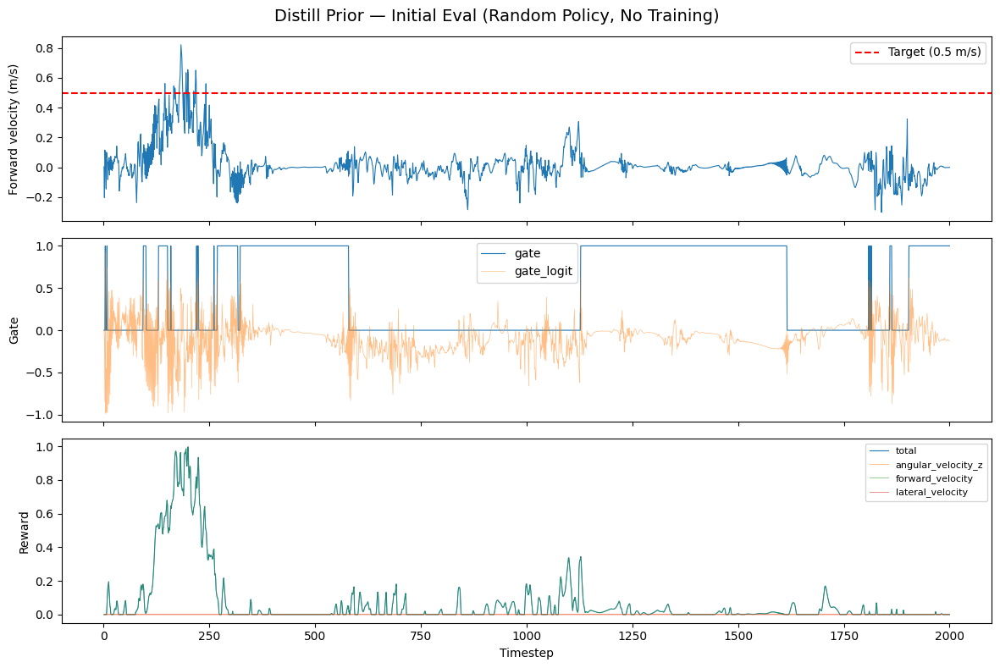

In [15]:
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)

timesteps = np.arange(1, len(rollout))

# Forward velocity
axes[0].plot(timesteps, qvel_x, linewidth=0.8)
axes[0].axhline(TARGET_SPEED, color="r", linestyle="--", label=f"Target ({TARGET_SPEED} m/s)")
axes[0].set_ylabel("Forward velocity (m/s)")
axes[0].legend()

# Gate
axes[1].plot(timesteps, gate_values, linewidth=0.8, label="gate")
axes[1].plot(timesteps, gate_logits, linewidth=0.5, alpha=0.5, label="gate_logit")
axes[1].set_ylabel("Gate")
axes[1].legend()

# Reward
axes[2].plot(timesteps, rewards, linewidth=0.8, label="total")
for k, vals in reward_breakdown.items():
    axes[2].plot(timesteps, vals, linewidth=0.5, alpha=0.7, label=k.split("/")[-1])
axes[2].set_ylabel("Reward")
axes[2].set_xlabel("Timestep")
axes[2].legend(fontsize=8)

fig.suptitle("Distill Prior — Initial Eval (Random Policy, No Training)", fontsize=14)
plt.tight_layout()
plt.show()

## Render video

In [17]:
import imageio
import mediapy

render_fps = 50

frames = env.render(
    rollout,
    camera="close_profile-rodent",
    height=480,
    width=640,
)

mediapy.show_video(frames, fps=render_fps)

100%|██████████| 2001/2001 [00:08<00:00, 245.77it/s]


This browser does not support the video tag.


In [ ]:
# Optionally save to file
# video_path = "distill_prior_initial_eval.mp4"
# with imageio.get_writer(video_path, fps=render_fps) as writer:
#     for frame in frames:
#         writer.append_data(frame)
# print(f"Saved to {video_path}")

## Pure RGM rollouts (self-contained)

Everything below is independent of the cells above. Loads the checkpoint,
builds the RGM policy, and runs rollouts in two environments:
1. **Maintain velocity** environment from a reference clip pose
2. **Imitation** environment (matches distill_prior training eval exactly)

In [1]:
%load_ext autoreload
%autoreload 2

import os

os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"
os.environ["PYOPENGL_PLATFORM"] = "egl"
os.environ["MUJOCO_GL"] = "egl"

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import mujoco
import mediapy
import orbax.checkpoint as ocp
from mujoco import mjx as mjx_module
from ml_collections import ConfigDict
from brax.training.acme import running_statistics
from omegaconf import OmegaConf

from scamper.environment.rodent import consts as rodent_consts
from scamper.environment.rodent import imitation
from scamper.environment.rodent import maintain_velocity as mv_module
from scamper.environment.reference_clips import ReferenceClips
from scamper.agent.task_transfer.maintain_velocity.observation_utils import (
    flatten_obs_dict,
)
from scamper.agent.task_transfer.maintain_velocity.checkpoint_utils import (
    make_decoder_inference_fn,
    make_rgm_inference_fn,
)
from scamper.agent.distill_prior.distill_prior_rollout_eval import (
    create_rgm_policy,
    extract_rgm_decoder_params,
)
from scamper.agent.distill_prior.distill_prior_networks import (
    create_abstract_distill_prior_policy,
)

In [2]:
# ---------- CONFIGURE ----------
DISTILL_PRIOR_CHECKPOINT_PATH = "/home/mila/a/aidan.sirbu/SCAMPER/scratch/distill_prior_checkpoints/260406_130524_381481"
DISTILL_PRIOR_CHECKPOINT_STEP = 54  # None = latest
XML_VARIANT = "limited-collisions"
CLIP_IDX = 2
FRAME_IDX = 0
SEED = 0
RENDER_FPS = 50
# -------------------------------

# Load full policy_params from checkpoint
step_prefix = "DistillPriorNetwork"
mgr_options = ocp.CheckpointManagerOptions(create=False, step_prefix=step_prefix)
with ocp.CheckpointManager(DISTILL_PRIOR_CHECKPOINT_PATH, options=mgr_options) as ckpt_mgr:
    ckpt_step = DISTILL_PRIOR_CHECKPOINT_STEP if DISTILL_PRIOR_CHECKPOINT_STEP is not None else ckpt_mgr.latest_step()
    ckpt_cfg = ckpt_mgr.restore(
        ckpt_step, args=ocp.args.Composite(config=ocp.args.JsonRestore())
    )["config"]

ckpt_cfg = OmegaConf.to_container(OmegaConf.create(ckpt_cfg))
rgm_hidden_layer_sizes = tuple(ckpt_cfg["network_config"]["rgm_layer_sizes"])

abstract_policy = create_abstract_distill_prior_policy(ckpt_cfg, rgm_hidden_layer_sizes)
with ocp.CheckpointManager(DISTILL_PRIOR_CHECKPOINT_PATH, options=mgr_options) as ckpt_mgr:
    policy_params = ckpt_mgr.restore(
        ckpt_step, args=ocp.args.Composite(policy=ocp.args.StandardRestore(abstract_policy))
    )["policy"]

latent_size = ckpt_cfg["network_config"]["intention_size"]
proprio_size = ckpt_cfg["network_config"]["obs_sizes"]["proprioception"]
action_size = ckpt_cfg["network_config"]["action_size"]

# Extract individual network params
normalizer_params, network_params = policy_params
rgm_params = network_params["params"]["rgm"]
decoder_params = network_params["params"]["decoder"]

# Load reference clips
clips = ReferenceClips(
    data_path="/home/mila/a/aidan.sirbu/SCAMPER/data/rodent/rodent_reference_clips.h5",
    n_frames_per_clip=250,
)

print(f"Checkpoint loaded: latent={latent_size}, proprio={proprio_size}, action={action_size}")
print(f"Clips: {clips.qpos.shape[0]} clips, {clips.qpos.shape[1]} frames each")

Checkpoint loaded: latent=16, proprio=277, action=38
Clips: 842 clips, 250 frames each


[MaintainVelocity] solver=Newton, iterations=5, ls_iterations=5, timestep=0.002, njmax=1000


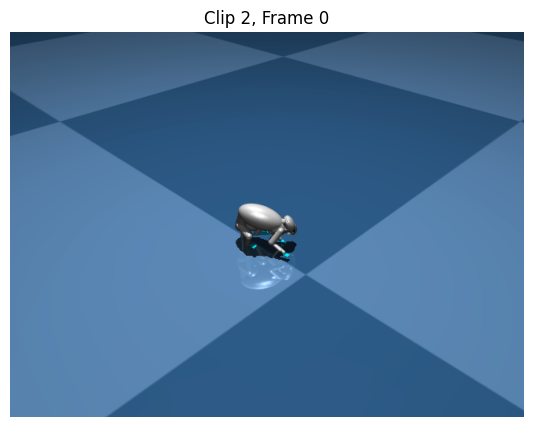

In [3]:
# Preview the chosen clip frame
ref = clips.at(clip=CLIP_IDX, frame=FRAME_IDX)

# Build maintain_velocity environment
bare_cfg = mv_module.default_config()
if XML_VARIANT == "limited-collisions":
    bare_cfg.walker_xml_path = rodent_consts.RODENT_XML_PATH
elif XML_VARIANT == "full-collisions":
    bare_cfg.walker_xml_path = rodent_consts.RODENT_FULL_COLLISION_XML
elif XML_VARIANT == "no-tail-collisions":
    bare_cfg.walker_xml_path = rodent_consts.RODENT_NO_TAIL_COLLISION_XML
bare_cfg.mujoco_impl = "jax"
bare_cfg.ctrl_dt = ckpt_cfg["env_config"]["ctrl_dt"]
bare_cfg.init_z = 0.0
bare_cfg.target_speed = 0.5
bare_cfg.torque_actuators = True
bare_env = mv_module.MaintainVelocity(config=bare_cfg)

# Debug: print solver settings
m = bare_env.mj_model
solver_names = {0: "PGS", 1: "CG", 2: "Newton"}
print(f"[MaintainVelocity] solver={solver_names.get(m.opt.solver, m.opt.solver)}, "
      f"iterations={m.opt.iterations}, ls_iterations={m.opt.ls_iterations}, "
      f"timestep={m.opt.timestep}, njmax={bare_cfg.njmax}")

# Render single frame preview
mj_data = mujoco.MjData(m)
mj_data.qpos = np.array(ref.qpos)
mj_data.qvel = np.zeros(m.nv)
mujoco.mj_forward(m, mj_data)

renderer = mujoco.Renderer(m, height=480, width=640)
renderer.update_scene(mj_data, camera="close_profile-rodent")
frame_img = renderer.render()
renderer.close()

plt.figure(figsize=(8, 5))
plt.imshow(frame_img)
plt.title(f"Clip {CLIP_IDX}, Frame {FRAME_IDX}")
plt.axis("off")
plt.show()

### 1. RGM rollout in maintain_velocity environment (clip-initialized)

In [5]:
# Build frozen inference functions for the maintain_velocity RGM loop
decoder_fn = make_decoder_inference_fn(decoder_params, normalizer_params, ckpt_cfg)
rgm_fn = make_rgm_inference_fn(rgm_params, normalizer_params, ckpt_cfg)

# Build maintain_velocity environment (now with prev_action bug fixed)
bare_cfg = mv_module.default_config()
bare_cfg.walker_xml_path = rodent_consts.RODENT_XML_PATH
bare_cfg.mujoco_impl = "jax"
bare_cfg.ctrl_dt = ckpt_cfg["env_config"]["ctrl_dt"]
bare_cfg.init_z = 0.0
bare_cfg.target_speed = 0.5
bare_cfg.torque_actuators = True
bare_env = mv_module.MaintainVelocity(config=bare_cfg)

jit_bare_step = jax.jit(bare_env.step)
jit_bare_reset = jax.jit(bare_env.reset)

# Reset and inject clip pose
rgm_state = jit_bare_reset(jax.random.PRNGKey(SEED))
init_data = rgm_state.data.replace(
    qpos=jnp.array(ref.qpos),
    qvel=jnp.array(ref.qvel),
)
init_data = mjx_module.forward(bare_env.mjx_model, init_data)
init_info = {"prev_action": bare_env.null_action(), "action": bare_env.null_action()}
init_obs = bare_env._get_obs(init_data, init_info)
rgm_state = rgm_state.replace(data=init_data, obs=init_obs, info=init_info)

# Rollout
rgm_rollout = [rgm_state]
rng_mv = jax.random.PRNGKey(SEED)
for _ in range(1000):
    rng_mv, key_action = jax.random.split(rng_mv)
    flat_obs = flatten_obs_dict(rgm_state.obs)
    proprio = flat_obs["proprioception"]
    rgm_mean, _ = rgm_fn(proprio)
    latent_proprio = jnp.concatenate([rgm_mean, proprio], axis=-1)
    ctrl, _ = decoder_fn(latent_proprio)
    rgm_state = jit_bare_step(rgm_state, ctrl)
    rgm_rollout.append(rgm_state)

print(f"Maintain velocity RGM rollout: {len(rgm_rollout)} states")


Maintain velocity RGM rollout: 1001 states


In [5]:
rgm_frames = bare_env.render(rgm_rollout, camera="close_profile-rodent", height=480, width=640)
mediapy.show_video(rgm_frames, fps=RENDER_FPS)

100%|██████████| 1001/1001 [00:04<00:00, 200.51it/s]


This browser does not support the video tag.


In [5]:
rgm_frames = bare_env.render(rgm_rollout, camera="close_profile-rodent", height=480, width=640)
mediapy.show_video(rgm_frames, fps=RENDER_FPS)

100%|██████████| 1001/1001 [00:05<00:00, 199.86it/s]


This browser does not support the video tag.


In [6]:
rgm_frames = bare_env.render(rgm_rollout, camera="close_profile-rodent", height=480, width=640)
mediapy.show_video(rgm_frames, fps=RENDER_FPS)

100%|██████████| 1001/1001 [00:05<00:00, 189.93it/s]


This browser does not support the video tag.


### 2. RGM rollout in imitation environment (matches distill_prior eval exactly)

In [6]:
# Create the imitation environment (same as distill_prior training)
imit_env_cfg = ConfigDict(ckpt_cfg["env_config"])

# Fix paths that point to /tmp/SCAMPER from training cluster
imit_env_cfg.walker_xml_path = str(rodent_consts.RODENT_XML_PATH)
imit_env_cfg.arena_xml_path = str(rodent_consts.ARENA_XML_PATH)
imit_env_cfg.reference_data_path = "data/rodent/rodent_reference_clips.h5"

imit_env = imitation.Imitation(config=imit_env_cfg, clips=clips)

# Debug: print solver settings
im = imit_env.mj_model
solver_names = {0: "PGS", 1: "CG", 2: "Newton"}
print(f"[Imitation] solver={solver_names.get(im.opt.solver, im.opt.solver)}, "
      f"iterations={im.opt.iterations}, ls_iterations={im.opt.ls_iterations}, "
      f"timestep={im.opt.timestep}, njmax={imit_env_cfg.njmax}")

# Build RGM policy using the exact same function as distill_prior eval
rgm_dp_params, decoder_dp_params, norm_dp_params = extract_rgm_decoder_params(policy_params)

imit_rgm_policy = create_rgm_policy(
    rgm_network_params=rgm_dp_params,
    decoder_network_params=decoder_dp_params,
    normalizer_params=norm_dp_params.proprioception,
    intention_latent_size=latent_size,
    action_size=action_size,
    proprioceptive_obs_size=proprio_size,
    decoder_hidden_layer_sizes=tuple(ckpt_cfg["network_config"]["decoder_layer_sizes"]),
    rgm_hidden_layer_sizes=rgm_hidden_layer_sizes,
    preprocess_observations_fn=running_statistics.normalize,
    fixed_logvar=0.0,
    deterministic=True,
)

# Rollout from the SAME clip pose as the maintain_velocity rollout
jit_imit_reset = jax.jit(imit_env.reset)
jit_imit_step = jax.jit(imit_env.step)

# Reset to get valid state structure, then inject the same clip pose
rng_imit = jax.random.PRNGKey(SEED)
imit_state = jit_imit_reset(rng_imit)
imit_init_data = imit_state.data.replace(
    qpos=jnp.array(ref.qpos),
    qvel=jnp.array(ref.qvel),
)
imit_init_data = mjx_module.forward(imit_env.mjx_model, imit_init_data)
imit_init_info = dict(imit_state.info)
imit_init_info["prev_action"] = imit_env.null_action()
imit_init_info["action"] = imit_env.null_action()
imit_init_obs = imit_env._get_obs(imit_init_data, imit_init_info)
imit_state = imit_state.replace(data=imit_init_data, obs=imit_init_obs, info=imit_init_info)

imit_rollout = [imit_state]
for _ in range(1000):
    rng_imit, key_action = jax.random.split(rng_imit)

    # Extract proprio from dict obs (same as distill_prior_rollout_eval.py lines 233-238)
    proprio = imit_state.obs.get("proprioception", imit_state.obs)
    if isinstance(proprio, dict):
        proprio, _ = jax.flatten_util.ravel_pytree(proprio)

    action, _ = imit_rgm_policy(proprio, key_action)
    imit_state = jit_imit_step(imit_state, action)
    imit_rollout.append(imit_state)

print(f"Imitation env RGM rollout: {len(imit_rollout)} states")

[Imitation] solver=Newton, iterations=5, ls_iterations=5, timestep=0.002, njmax=1000


Imitation env RGM rollout: 1001 states


In [7]:
imit_frames = imit_env.render(imit_rollout, camera="close_profile-rodent", height=480, width=640)
mediapy.show_video(imit_frames, fps=RENDER_FPS)

This browser does not support the video tag.


In [8]:
imit_frames = imit_env.render(imit_rollout, camera="close_profile-rodent", height=480, width=640)
mediapy.show_video(imit_frames, fps=RENDER_FPS)

This browser does not support the video tag.


### Debug: compare first step numerically between both envs

In [12]:
# Compare initial proprio, RGM output, decoder ctrl, and resulting qpos

# --- MaintainVelocity env ---
mv_proprio_0 = flatten_obs_dict(rgm_rollout[0].obs)["proprioception"]
mv_proprio_1 = flatten_obs_dict(rgm_rollout[1].obs)["proprioception"]

# --- Imitation env ---
im_p0 = imit_rollout[0].obs.get("proprioception", imit_rollout[0].obs)
im_proprio_0 = jax.flatten_util.ravel_pytree(im_p0)[0] if isinstance(im_p0, dict) else im_p0

im_p1 = imit_rollout[1].obs.get("proprioception", imit_rollout[1].obs)
im_proprio_1 = jax.flatten_util.ravel_pytree(im_p1)[0] if isinstance(im_p1, dict) else im_p1

print("=== Step 0: Initial state ===")
print("qpos match:", bool(jnp.allclose(rgm_rollout[0].data.qpos, imit_rollout[0].data.qpos)))
print("qvel match:", bool(jnp.allclose(rgm_rollout[0].data.qvel, imit_rollout[0].data.qvel)))
print("proprio shape: mv=", mv_proprio_0.shape, "im=", im_proprio_0.shape)
print("proprio match:", bool(jnp.allclose(mv_proprio_0, im_proprio_0)))
if not jnp.allclose(mv_proprio_0, im_proprio_0):
    diff = jnp.abs(mv_proprio_0 - im_proprio_0)
    print("  max diff:", float(jnp.max(diff)), "at idx", int(jnp.argmax(diff)))
    nonzero = jnp.where(diff > 1e-6)[0]
    print("  indices with diff > 1e-6:", nonzero.tolist()[:20])
    for idx in nonzero[:10]:
        print(f"    [{int(idx)}] mv={float(mv_proprio_0[idx]):.8f} im={float(im_proprio_0[idx]):.8f}")

# Compute ctrl from both paths
mv_rgm_mean, _ = rgm_fn(mv_proprio_0)
mv_latent_proprio = jnp.concatenate([mv_rgm_mean, mv_proprio_0], axis=-1)
mv_ctrl_0, _ = decoder_fn(mv_latent_proprio)

im_action_0, im_extras_0 = imit_rgm_policy(im_proprio_0, jax.random.PRNGKey(42))

print("\n=== RGM + Decoder outputs ===")
print("rgm_mean match:", bool(jnp.allclose(mv_rgm_mean, im_extras_0['rgm_mean'])))
print("ctrl match:", bool(jnp.allclose(mv_ctrl_0, im_action_0, atol=1e-5)))
if not jnp.allclose(mv_ctrl_0, im_action_0, atol=1e-5):
    ctrl_diff = jnp.abs(mv_ctrl_0 - im_action_0)
    print("  ctrl max diff:", float(jnp.max(ctrl_diff)))

print("\n=== Step 1: After first step ===")
print("qpos match:", bool(jnp.allclose(rgm_rollout[1].data.qpos, imit_rollout[1].data.qpos, atol=1e-5)))
if not jnp.allclose(rgm_rollout[1].data.qpos, imit_rollout[1].data.qpos, atol=1e-5):
    qpos_diff = jnp.abs(rgm_rollout[1].data.qpos - imit_rollout[1].data.qpos)
    print("  qpos max diff:", float(jnp.max(qpos_diff)), "at idx", int(jnp.argmax(qpos_diff)))
print("qvel match:", bool(jnp.allclose(rgm_rollout[1].data.qvel, imit_rollout[1].data.qvel, atol=1e-5)))
print("proprio match (step 1):", bool(jnp.allclose(mv_proprio_1, im_proprio_1, atol=1e-5)))
if not jnp.allclose(mv_proprio_1, im_proprio_1, atol=1e-5):
    p_diff = jnp.abs(mv_proprio_1 - im_proprio_1)
    print("  proprio max diff:", float(jnp.max(p_diff)), "at idx", int(jnp.argmax(p_diff)))


=== Step 0: Initial state ===
qpos match: True
qvel match: True
proprio shape: mv= (277,) im= (277,)
proprio match: False
  max diff: 0.000133514404296875 at idx 228
  indices with diff > 1e-6: [226, 227, 228]
    [226] mv=47.24554062 im=47.24544525
    [227] mv=-129.53291321 im=-129.53297424
    [228] mv=1.16828680 im=1.16842031

=== RGM + Decoder outputs ===
rgm_mean match: True
ctrl match: True

=== Step 1: After first step ===
qpos match: True
qvel match: True
proprio match (step 1): True


[MaintainVelocity]
  Mean RMS jerk:  4345.46
  Max RMS jerk:   19343.98
  Mean RMS accel: 40.22
  Steps: 1001
[Imitation]
  Mean RMS jerk:  4633.38
  Max RMS jerk:   21409.19
  Mean RMS accel: 41.34
  Steps: 1001


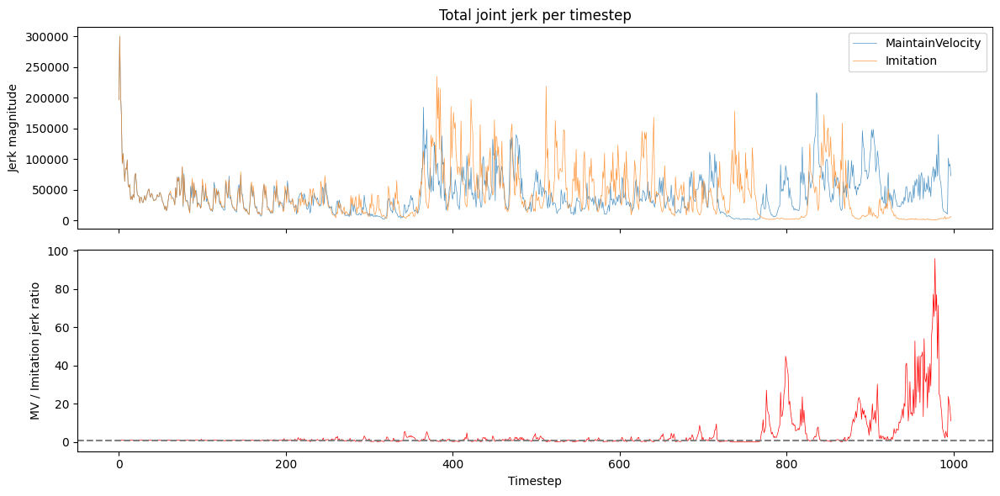


Mean jerk ratio (MV/Imit): 4.019


In [9]:
# Quantify jitter: compare joint angle jerk (3rd derivative of qpos) between rollouts

def compute_jitter_metrics(rollout_states, dt, label):
    """Compute jerk-based jitter metrics from a rollout."""
    # Extract joint angles (qpos[7:]) for each step, skip root freejoint
    joint_angles = jnp.stack([s.data.qpos[7:] for s in rollout_states])
    
    # Velocity (1st derivative)
    vel = jnp.diff(joint_angles, axis=0) / dt
    # Acceleration (2nd derivative)
    acc = jnp.diff(vel, axis=0) / dt
    # Jerk (3rd derivative)
    jerk = jnp.diff(acc, axis=0) / dt
    
    # RMS jerk per joint, then mean across joints
    rms_jerk_per_joint = jnp.sqrt(jnp.mean(jerk ** 2, axis=0))
    mean_rms_jerk = float(jnp.mean(rms_jerk_per_joint))
    max_rms_jerk = float(jnp.max(rms_jerk_per_joint))
    
    # Also compute RMS acceleration (smoothness)
    rms_acc_per_joint = jnp.sqrt(jnp.mean(acc ** 2, axis=0))
    mean_rms_acc = float(jnp.mean(rms_acc_per_joint))
    
    # Per-step total jerk magnitude
    jerk_magnitude = jnp.sqrt(jnp.sum(jerk ** 2, axis=-1))  # (T-3,)
    
    print(f"[{label}]")
    print(f"  Mean RMS jerk:  {mean_rms_jerk:.2f}")
    print(f"  Max RMS jerk:   {max_rms_jerk:.2f}")
    print(f"  Mean RMS accel: {mean_rms_acc:.2f}")
    print(f"  Steps: {len(rollout_states)}")
    
    return jerk_magnitude

dt = ckpt_cfg["env_config"]["ctrl_dt"]

mv_jerk = compute_jitter_metrics(rgm_rollout, dt, "MaintainVelocity")
im_jerk = compute_jitter_metrics(imit_rollout, dt, "Imitation")

# Plot jerk over time
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

axes[0].plot(mv_jerk, linewidth=0.5, alpha=0.8, label="MaintainVelocity")
axes[0].plot(im_jerk, linewidth=0.5, alpha=0.8, label="Imitation")
axes[0].set_ylabel("Jerk magnitude")
axes[0].legend()
axes[0].set_title("Total joint jerk per timestep")

# Ratio
min_len = min(len(mv_jerk), len(im_jerk))
ratio = mv_jerk[:min_len] / jnp.clip(im_jerk[:min_len], 1e-8)
axes[1].plot(ratio, linewidth=0.5, color='red')
axes[1].axhline(1.0, color='gray', linestyle='--')
axes[1].set_ylabel("MV / Imitation jerk ratio")
axes[1].set_xlabel("Timestep")

plt.tight_layout()
plt.show()

print(f"\nMean jerk ratio (MV/Imit): {float(jnp.mean(ratio)):.3f}")
